Note: you may need to restart the kernel to use updated packages.
  Cloning https://github.com/openai/CLIP.git to C:\Users\17001\AppData\Local\Temp\pip-req-build-3724aqql
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Note: you may need to restart the kernel to use updated packages.


  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git 'C:\Users\17001\AppData\Local\Temp\pip-req-build-3724aqql'


c:\Users\17001\anaconda3\envs\torch_env\lib\site-packages\clip\__init__.py


100%|███████████████████████████████████████| 244M/244M [00:25<00:00, 10.0MiB/s]


load success
image feature shape: torch.Size([4, 1024])
text feature shape: torch.Size([4, 1024])
相似度矩阵:
 [[0.26593548 0.24323657 0.18762669 0.1604976 ]
 [0.19468229 0.26287782 0.17988494 0.1626249 ]
 [0.14602429 0.12872186 0.21079507 0.14595518]
 [0.15797807 0.14925426 0.1721837  0.23177972]]


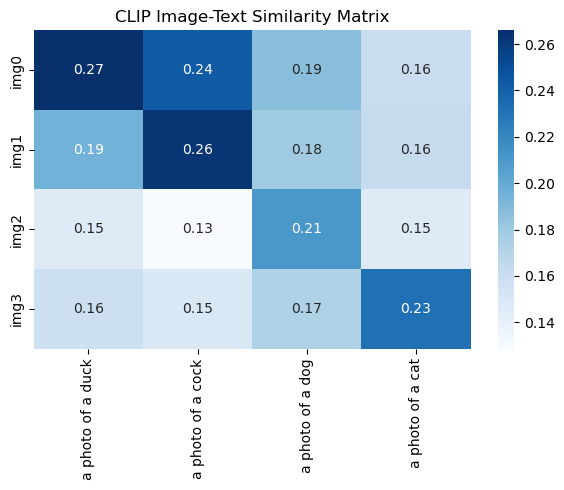

In [1]:
%pip install torch torchvision 
%pip install git+https://github.com/openai/CLIP.git
import clip
print(clip.__file__)

import torch
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = clip.load("RN50", device=device)
print("load success")

img_paths = ["img1.jpg", "img2.jpg", "img3.jpg", "img4.jpg"]
texts = [
    "a photo of a duck",
    "a photo of a cock",
    "a photo of a dog",
    "a photo of a cat"
]

images = []
for p in img_paths:
    im = preprocess(Image.open(p)).unsqueeze(0).to(device)
    images.append(im)
image_tensor = torch.cat(images)

text_tokens = clip.tokenize(texts).to(device)

with torch.no_grad():
    image_features = model.encode_image(image_tensor)
    text_features = model.encode_text(text_tokens)

image_features = image_features / image_features.norm(dim=-1, keepdim=True)
text_features = text_features / text_features.norm(dim=-1, keepdim=True)

print("image feature shape:", image_features.shape)
print("text feature shape:", text_features.shape)

sim_matrix = (image_features @ text_features.T).cpu().numpy()
print("相似度矩阵:\n", sim_matrix)

plt.figure(figsize=(6,5))
sns.heatmap(sim_matrix, annot=True, xticklabels=texts, yticklabels=[f"img{i}" for i in range(4)], cmap="Blues")
plt.title("CLIP Image-Text Similarity Matrix")
plt.tight_layout()
plt.savefig("clip_heatmap.png")
plt.show()